# Módulo 1 — Modelos de Referencia (General vs. Específico por Ruta), Residuos e IC

Comparamos de forma precisa y con código sencillo tres enfoques de referencia (antes de integrar redes neuronales):
1. **Ingenuo Estacional (Base):** mismo día de la semana más reciente conocido en el origen $t$.
2. **GLM Poisson General (global):** un único modelo para las 848 rutas (intercepto propio por ruta, pero coeficientes de calendario y rezagos compartidos).
3. **GLM Poisson Específico (por ruta):** un modelo independiente para cada una de las 848 rutas (cada ruta aprende su propio perfil semanal, festivos/puentes y rezagos).

Evaluamos en **3 ventanas rodantes de 30 días** (oct-2025, nov-2025 y mar-2026) con cero fuga de información a 30 días, incluyendo análisis de **residuos** e **Intervalos de Predicción (IC 80% y IC 90%)**.

## 1. Carga del modelo ganador y métricas de prueba

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

SRC_DIR = Path("../src").resolve()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from flota import dimensionar
from modelos_referencia import (
    METRICAS_REF_CSV,
    METRICAS_RUTA_CSV,
    MODEL_PATH,
    PRONOSTICOS_30D_CSV,
    RUTAS_CSV,
    entrenar_y_evaluar,
)

FIGURES_DIR = Path("../figures").resolve()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

if not MODEL_PATH.exists():
    entrenar_y_evaluar()

artefacto = joblib.load(MODEL_PATH)
metricas = pd.read_csv(METRICAS_REF_CSV)
metricas_ruta = pd.read_csv(METRICAS_RUTA_CSV)
pron_30d = pd.read_csv(PRONOSTICOS_30D_CSV, parse_dates=["fecha"])
rutas = pd.read_csv(RUTAS_CSV)

pct_gana_esp = (metricas_ruta["MAE_especifico"] < metricas_ruta["MAE_general"]).mean() * 100
print(f"Modelo ganador en validacion: {artefacto['nombre_modelo']}")
print(f"MAE validacion | General (global): {artefacto['mae_val_general']:.2f} vs Especifico (por ruta): {artefacto['mae_val_especifico']:.2f}")
print(f"En prueba, el modelo Especifico (por ruta) vence al General (global) en {pct_gana_esp:.1f}% de las {len(metricas_ruta)} rutas.")

C:\Users\ADMON\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.stats import gaussian_kde


Modelo ganador en validacion: GLM_Poisson_Especifico_PorRuta
MAE validacion | General (global): 62.01 vs Especifico (por ruta): 55.28
En prueba, el modelo Especifico (por ruta) vence al General (global) en 65.3% de las 848 rutas.


## 2. Comparativa de métricas: Ingenuo vs. General (global) vs. Específico (por ruta)

,modelo,tipo,segmento,MAE,RMSE,MASE,Pinball_p50,Pinball_p75,Pinball_p90,Pinball_p95,Cobertura_IC80_pct,Cobertura_IC90_pct
0,Ingenuo_Estacional,Base,Global (dias 1-30),77.58,201.15,1.1738,NaN,NaN,NaN,NaN,NaN,NaN
1,GLM_Poisson_General_Global,General (global),Global (dias 1-30),70.86,168.41,1.0721,35.43,29.79,18.80,12.40,75.28,85.99
2,GLM_Poisson_Especifico_PorRuta,Específico (por ruta),Global (dias 1-30),66.55,164.77,1.0068,33.27,28.47,18.26,12.05,74.32,84.80
3,Ingenuo_Estacional,Base,Horizonte dias 1-7,76.72,193.00,1.1608,NaN,NaN,NaN,NaN,NaN,NaN
4,GLM_Poisson_General_Global,General (global),Horizonte dias 1-7,73.14,164.90,1.1067,36.57,30.74,19.18,12.57,73.60,85.34
5,GLM_Poisson_Especifico_PorRuta,Específico (por ruta),Horizonte dias 1-7,67.22,152.63,1.0171,33.61,28.46,17.95,11.71,73.31,84.43
6,Ingenuo_Estacional,Base,Horizonte dias 8-14,79.42,202.70,1.2016,NaN,NaN,NaN,NaN,NaN,NaN
7,GLM_Poisson_General_Global,General (global),Horizonte dias 8-14,69.39,166.31,1.0499,34.70,30.48,19.92,13.50,76.94,87.90
8,GLM_Poisson_Especifico_PorRuta,Específico (por ruta),Horizonte dias 8-14,62.89,154.20,0.9516,31.45,27.76,18.08,12.06,76.51,87.34
9,Ingenuo_Estacional,Base,Horizonte dias 15-30,77.15,203.95,1.1672,NaN,NaN,NaN,NaN,NaN,NaN


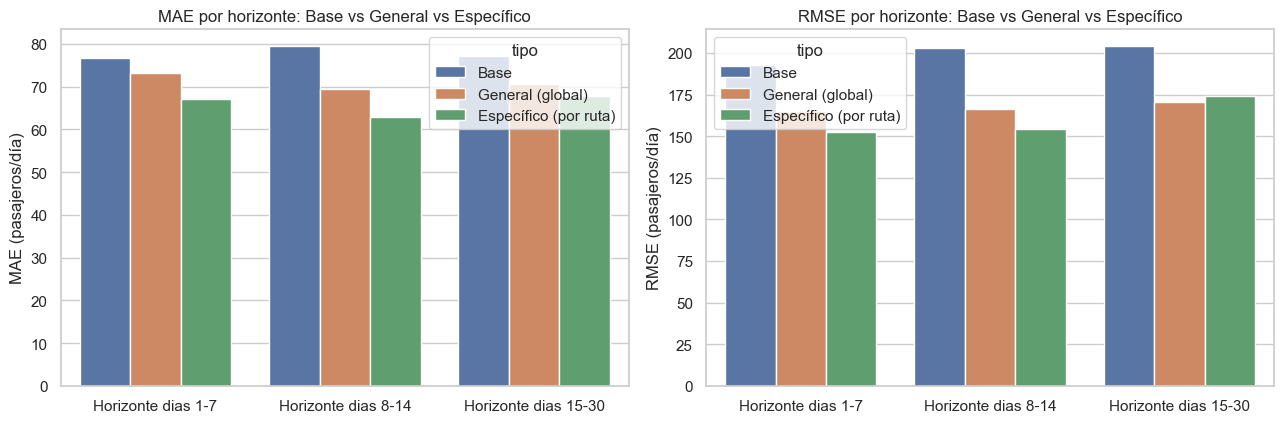

In [2]:
display(metricas)

hor = metricas[metricas["segmento"].str.startswith("Horizonte")].copy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))

sns.barplot(data=hor, x="segmento", y="MAE", hue="tipo", ax=ax1)
ax1.set_title("MAE por horizonte: Base vs General vs Específico")
ax1.set_xlabel("")
ax1.set_ylabel("MAE (pasajeros/día)")

sns.barplot(data=hor, x="segmento", y="RMSE", hue="tipo", ax=ax2)
ax2.set_title("RMSE por horizonte: Base vs General vs Específico")
ax2.set_xlabel("")
ax2.set_ylabel("RMSE (pasajeros/día)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "ref_01_error_por_horizonte.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Evaluación de residuos del modelo ganador (Específico por ruta, marzo 2026)

C:\Users\ADMON\AppData\Local\Temp\ipykernel_8204\2524296999.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  eval_df["dia_semana"] = eval_df["fecha"].dt.dayofweek


,Valor
"Media residuo (sesgo, pax)",-10.467
Mediana residuo (pax),-0.800
Desv. estandar residuo (pax),201.213
Media residuo (log1p),-0.399
Desv. estandar (log1p),1.418
Asimetria (log1p),-2.924
Curtosis exceso (log1p),8.157
"Cobertura IC 80% [P10, P90] (%)",68.892
"Cobertura IC 90% [P05, P95] (%)",79.733


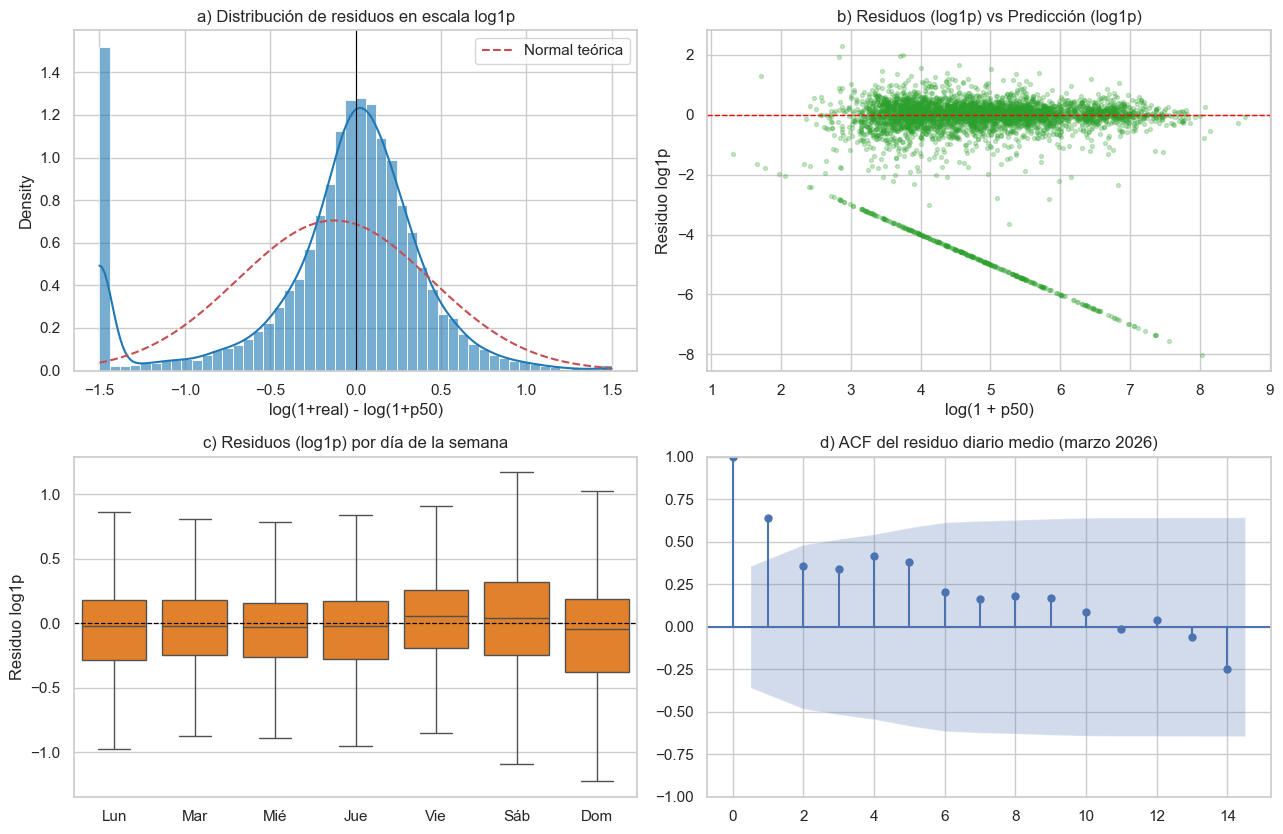

In [3]:
eval_df = pron_30d.merge(rutas[["ruta_id", "ruta_nombre", "dist_linea_recta_km"]], on="ruta_id", how="left")
eval_df["residuo"] = eval_df["real"] - eval_df["p50"]
eval_df["residuo_log"] = np.log1p(eval_df["real"]) - np.log1p(eval_df["p50"])
eval_df["dia_semana"] = eval_df["fecha"].dt.dayofweek

res_stats = pd.Series({
    "Media residuo (sesgo, pax)": eval_df["residuo"].mean(),
    "Mediana residuo (pax)": eval_df["residuo"].median(),
    "Desv. estandar residuo (pax)": eval_df["residuo"].std(),
    "Media residuo (log1p)": eval_df["residuo_log"].mean(),
    "Desv. estandar (log1p)": eval_df["residuo_log"].std(),
    "Asimetria (log1p)": stats.skew(eval_df["residuo_log"]),
    "Curtosis exceso (log1p)": stats.kurtosis(eval_df["residuo_log"]),
    "Cobertura IC 80% [P10, P90] (%)": ((eval_df["real"] >= eval_df["p10"]) & (eval_df["real"] <= eval_df["p90"])).mean() * 100,
    "Cobertura IC 90% [P05, P95] (%)": ((eval_df["real"] >= eval_df["p05"]) & (eval_df["real"] <= eval_df["p95"])).mean() * 100,
}).round(3)
display(res_stats.to_frame("Valor"))

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

r_log = eval_df["residuo_log"].clip(-1.5, 1.5)
sns.histplot(r_log, bins=50, stat="density", kde=True, ax=axes[0, 0], color="#1f77b4", alpha=0.6)
xs = np.linspace(-1.5, 1.5, 200)
axes[0, 0].plot(xs, stats.norm.pdf(xs, r_log.mean(), r_log.std()), "r--", lw=1.5, label="Normal teórica")
axes[0, 0].axvline(0, color="black", lw=0.8)
axes[0, 0].set_title("a) Distribución de residuos en escala log1p")
axes[0, 0].set_xlabel("log(1+real) - log(1+p50)")
axes[0, 0].legend()

sample = eval_df.sample(min(4000, len(eval_df)), random_state=42)
axes[0, 1].scatter(np.log1p(sample["p50"]), sample["residuo_log"], s=8, alpha=0.25, color="#2ca02c")
axes[0, 1].axhline(0, color="red", ls="--", lw=1)
axes[0, 1].set_title("b) Residuos (log1p) vs Predicción (log1p)")
axes[0, 1].set_xlabel("log(1 + p50)")
axes[0, 1].set_ylabel("Residuo log1p")

dias_lbl = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
sns.boxplot(data=eval_df, x="dia_semana", y="residuo_log", showfliers=False, ax=axes[1, 0], color="#ff7f0e")
axes[1, 0].axhline(0, color="black", ls="--", lw=0.9)
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(dias_lbl)
axes[1, 0].set_title("c) Residuos (log1p) por día de la semana")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Residuo log1p")

res_diario = eval_df.groupby("fecha")["residuo_log"].mean().sort_index()
plot_acf(res_diario, lags=14, ax=axes[1, 1], title="d) ACF del residuo diario medio (marzo 2026)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "ref_02_diagnostico_residuos.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Pronósticos e IC: Específico (por ruta) vs. General (global) en marzo 2026

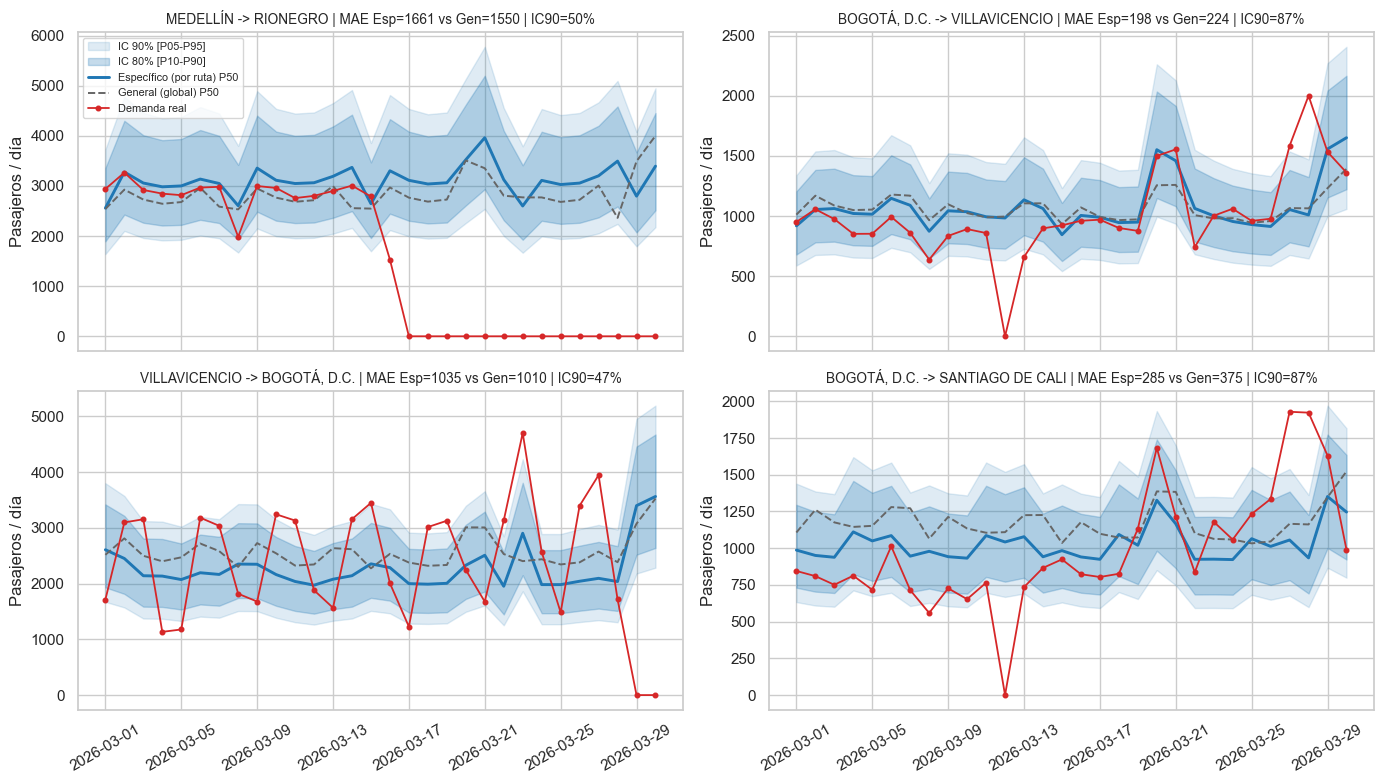

In [4]:
rutas_ejemplo = ["05001_05615", "11001_50001", "50001_11001", "11001_76001"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

for ax, rid in zip(axes.flat, rutas_ejemplo):
    sub = eval_df[eval_df["ruta_id"] == rid].sort_values("fecha")
    nombre = sub["ruta_nombre"].iloc[0]
    cob90 = ((sub["real"] >= sub["p05"]) & (sub["real"] <= sub["p95"])).mean() * 100
    mae_e = np.mean(np.abs(sub["real"] - sub["p50_especifico"]))
    mae_g = np.mean(np.abs(sub["real"] - sub["p50_general"]))

    ax.fill_between(sub["fecha"], sub["p05"], sub["p95"], color="#1f77b4", alpha=0.14, label="IC 90% [P05-P95]")
    ax.fill_between(sub["fecha"], sub["p10"], sub["p90"], color="#1f77b4", alpha=0.26, label="IC 80% [P10-P90]")
    ax.plot(sub["fecha"], sub["p50_especifico"], color="#1f77b4", lw=2.1, label="Específico (por ruta) P50")
    ax.plot(sub["fecha"], sub["p50_general"], color="#666666", lw=1.4, ls="--", label="General (global) P50")
    ax.plot(sub["fecha"], sub["real"], color="#d62728", marker="o", ms=3.3, lw=1.3, label="Demanda real")
    ax.set_title(f"{nombre} | MAE Esp={mae_e:.0f} vs Gen={mae_g:.0f} | IC90={cob90:.0f}%", fontsize=9.8)
    ax.set_ylabel("Pasajeros / día")
    ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend(loc="upper left", fontsize=7.8)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "ref_03_pronosticos_e_ic_mar2026.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Dimensionamiento operativo de ejemplo (`src/flota.py`)

In [5]:
rid_demo = "11001_76001"
sub_demo = eval_df[eval_df["ruta_id"] == rid_demo].sort_values("fecha").set_index("fecha")
dist_km = float(sub_demo["dist_linea_recta_km"].iloc[0])

flota_p50 = dimensionar(sub_demo["p50"], {"dist_linea_recta_km": dist_km, "ocupacion_objetivo": 0.80})
flota_p90 = dimensionar(sub_demo["p90"], {"dist_linea_recta_km": dist_km, "ocupacion_objetivo": 0.80})

resumen_op = pd.DataFrame({
    "Escenario": ["Pronóstico puntual (P50)", "Cuantil alto (P90)"],
    "Pasajeros prom/día": [flota_p50["demanda"].mean(), flota_p90["demanda"].mean()],
    "Despachos prom/día": [flota_p50["despachos"].mean(), flota_p90["despachos"].mean()],
    "Buses prom/día": [flota_p50["vehiculos"].mean(), flota_p90["vehiculos"].mean()],
    "Buses pico (máx)": [flota_p50["vehiculos"].max(), flota_p90["vehiculos"].max()],
    "Conductores prom/día": [flota_p50["conductores"].mean(), flota_p90["conductores"].mean()],
    "Conductores pico (máx)": [flota_p50["conductores"].max(), flota_p90["conductores"].max()],
}).round(1)
display(resumen_op)

,Escenario,Pasajeros prom/día,Despachos prom/día,Buses prom/día,Buses pico (máx),Conductores prom/día,Conductores pico (máx)
0,Pronóstico puntual (P50),1032.1,32.6,34.7,46,88.0,116
1,Cuantil alto (P90),1354.3,42.8,45.3,59,114.5,149
